# Machine Learning: Exercise session 07

In this exercise session we will focus on tree bagging and random forests for the practical parts.

The theoretical exercise is about the properties of bootstrap. We will derive the probability that a given observation is part of a bootstrap sample.

## 0. Data import and Cleaning

In [1]:
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, train_test_split, GridSearchCV

Import the "Heart" dataset, containing demographic and medical informations about a list of patients. Drop `NA` values, convert the categorical variables into the desired pandas type: "category", and perform any other necessary data cleaning.

In [6]:
data = pd.read_csv('Heart_ISL.csv')
print(data.head())

   Unnamed: 0  Age  Sex     ChestPain  RestBP  Chol  Fbs  RestECG  MaxHR  \
0           1   63    1       typical     145   233    1        2    150   
1           2   67    1  asymptomatic     160   286    0        2    108   
2           3   67    1  asymptomatic     120   229    0        2    129   
3           4   37    1    nonanginal     130   250    0        0    187   
4           5   41    0    nontypical     130   204    0        2    172   

   ExAng  Oldpeak  Slope   Ca        Thal  AHD  
0      0      2.3      3  0.0       fixed   No  
1      1      1.5      2  3.0      normal  Yes  
2      1      2.6      2  2.0  reversable  Yes  
3      0      3.5      3  0.0      normal   No  
4      0      1.4      1  0.0      normal   No  


In [7]:
#count Na
print("Number of NaN values in each column:")
print(data.isna().sum())
#drop NaN values
data = data.dropna()

#check for categorical variuables ancd change type to category
categorical_columns = data.select_dtypes(include=['object']).columns
for col in categorical_columns:
    data[col] = data[col].astype('category')
    
#check if it all worked
print("Data types after conversion:")
print(data.dtypes)


Number of NaN values in each column:
Unnamed: 0    0
Age           0
Sex           0
ChestPain     0
RestBP        0
Chol          0
Fbs           0
RestECG       0
MaxHR         0
ExAng         0
Oldpeak       0
Slope         0
Ca            4
Thal          2
AHD           0
dtype: int64
Data types after conversion:
Unnamed: 0       int64
Age              int64
Sex              int64
ChestPain     category
RestBP           int64
Chol             int64
Fbs              int64
RestECG          int64
MaxHR            int64
ExAng            int64
Oldpeak        float64
Slope            int64
Ca             float64
Thal          category
AHD           category
dtype: object


/var/folders/63/kcd0h_715xq8ng5979jf4c1m0000gn/T/ipykernel_18793/2870431366.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = data.select_dtypes(include=['object']).columns


The response variable that we will try to predict is "AHD", that indicates whether the patient has a heart disease.

Now split the data into the features `X` and the response `y`.

As, sadly, trees in sklearn do not handle categorical features directly, transform `X`'s categorical variables into "dummies". This can be achieved either with panda's `pd.get_dummies(<data>, drop_first=True)` or sklearn's `OneHotEncoder`. Make sure that you keep X in dataframe format, and keep feature/column names.

In [12]:
X = data.drop('AHD', axis=1)
y = data['AHD']
X = pd.get_dummies(X, drop_first=True)

Split the data into train and test. Set random_state=40 and leave 20% of the data out for the test set.

In [13]:
np.random.seed(40)
#split the data into training and test sets, with 80% of the data for training and 20% for testing.

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

## 1. Bagging and Random Forests

In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree

### 1.1 Forest of trees

Fit a random forest, with 200 trees and default values for the other hyper-parameters, to the heart dataset. Then plot three of the forest's trees.

Then do the same for a tree bagging model. What is the only hyper-parameter to change in the `RandomForestClassifier` to obtain a tree bagging model?

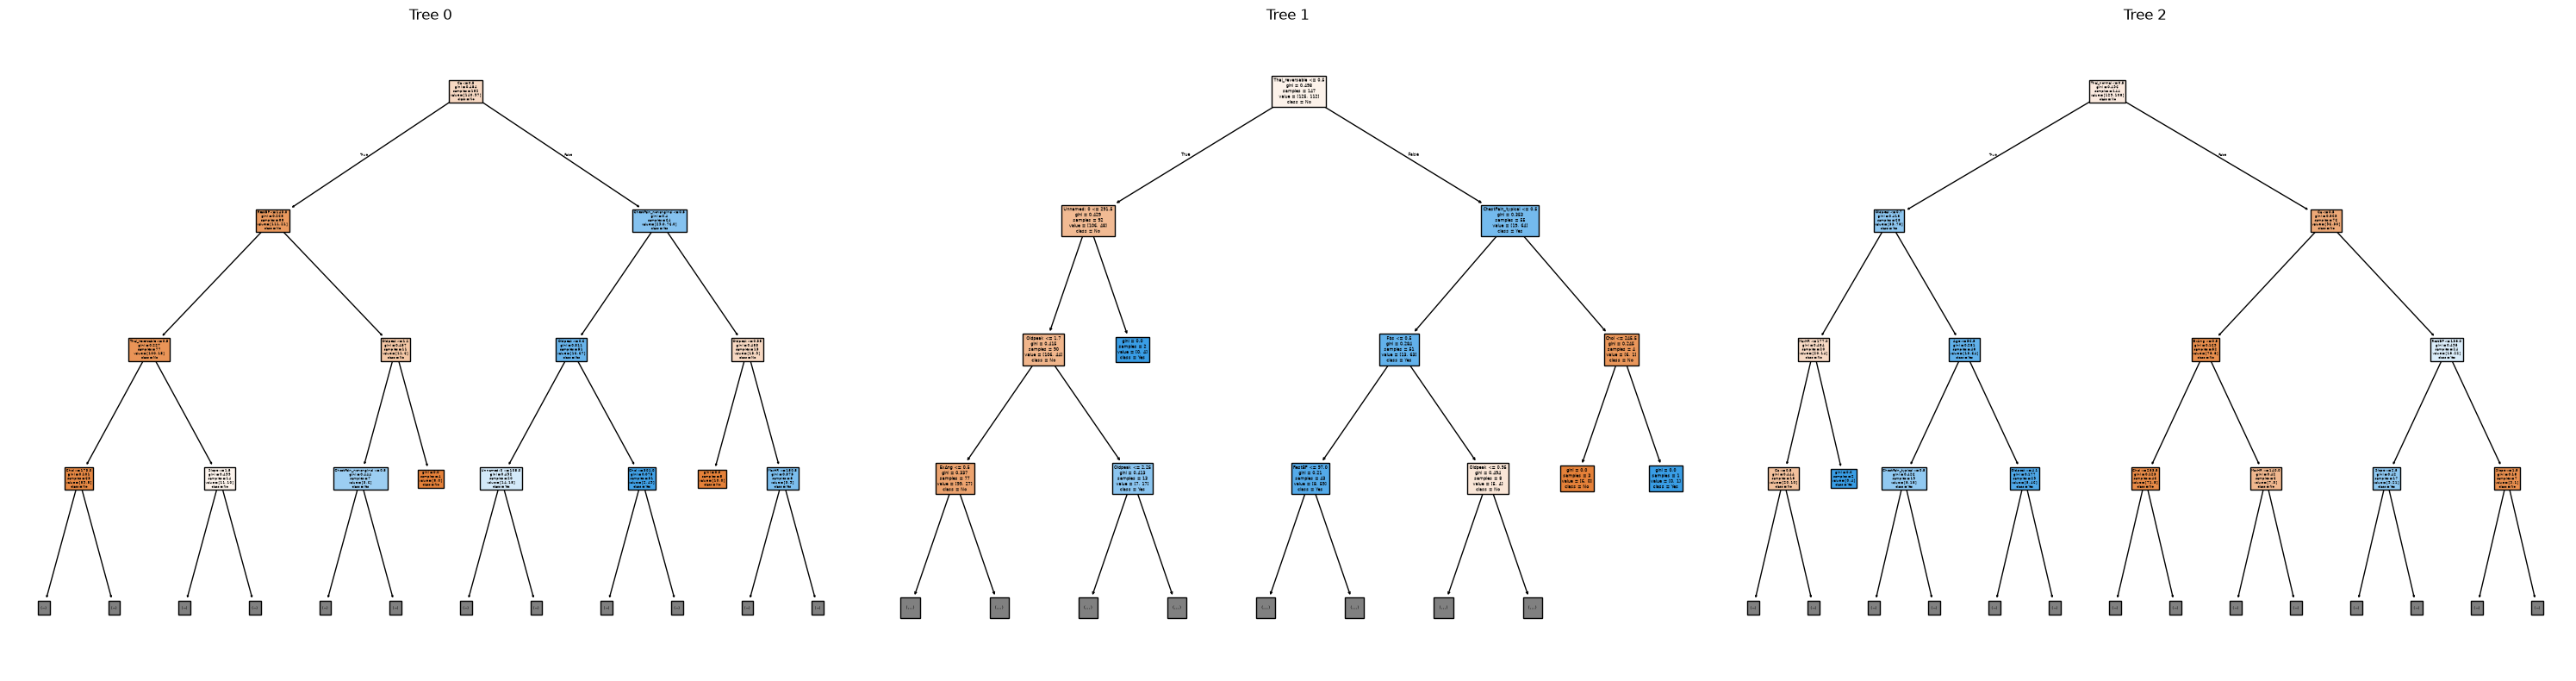

In [17]:
rf = RandomForestClassifier(n_estimators=200)
rf.fit(X_train, y_train)
fig, axes = plt.subplots(1, 3, figsize=(30, 8))

for i, ax in enumerate(axes):
    plot_tree(
        rf.estimators_[i],
        feature_names=X_train.columns,
        class_names=rf.classes_.astype(str),
        filled=True,
        max_depth=3,
        ax=ax,
    )
    ax.set_title(f"Tree {i}")

plt.tight_layout()
plt.show()


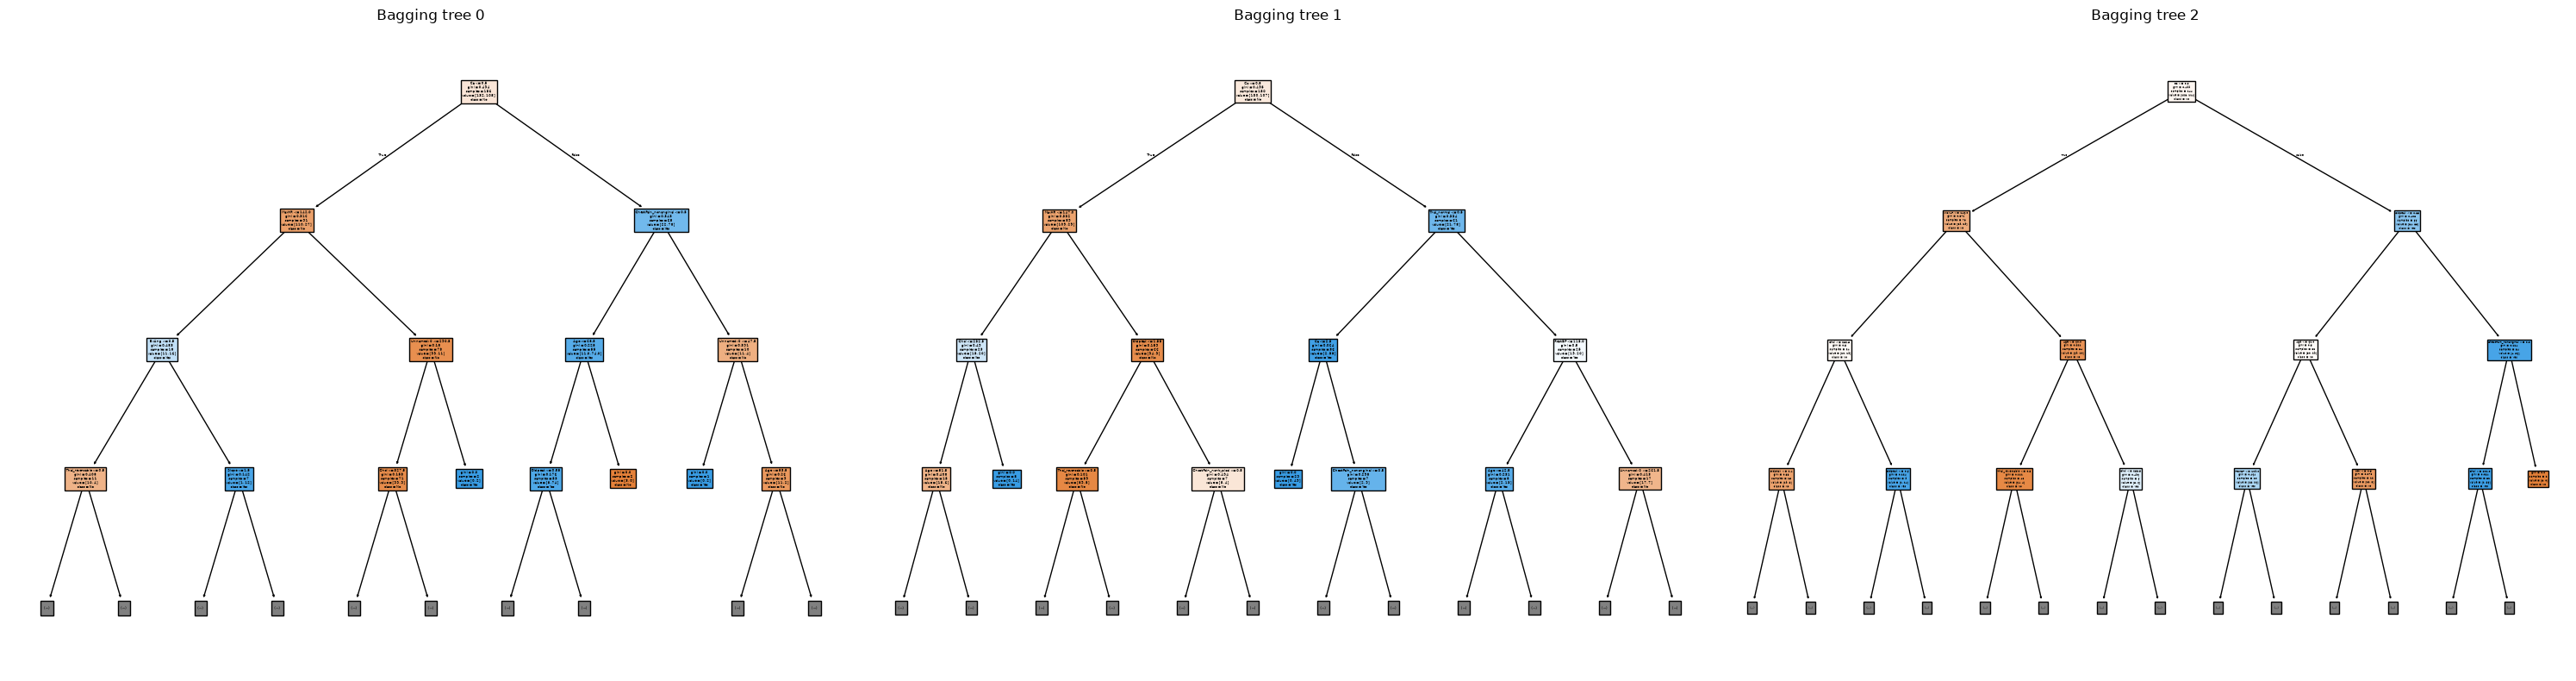

In [18]:
from sklearn.ensemble import BaggingClassifier

bag = BaggingClassifier(n_estimators=200)
bag.fit(X_train, y_train)
fig, axes = plt.subplots(1, 3, figsize=(30, 8))

for i, ax in enumerate(axes):
    plot_tree(
        bag.estimators_[i],
        feature_names=X_train.columns,
        class_names=bag.classes_.astype(str),
        filled=True,
        max_depth=3,
        ax=ax,
    )
    ax.set_title(f"Bagging tree {i}")

plt.tight_layout()
plt.show()

### 1.2 Tune the Forest

Now tune the hyper-parameters "max_features" and "min_samples_leaf" of the Random Forest classifier to minimize the expected generalization error.

You could use cross-validation. Is there another way to get the desired estimate other than with cross-validation? Use 2000 trees per forest or more.

_Hint:_ `sklearn.model_selection.ParameterGrid` and `<RF_instance>.set_params(...)` might be useful.

_Tip:_ In sklearn, you can set `n_jobs=-1` (or `n_jobs=-2`) in some models and in grid searches to use all (or all but one) of your computer's cores in parallel, which can reduce the running time depending on your computer. Be careful not to "nest" the parallelization.

In [19]:
from sklearn.model_selection import ParameterGrid

param_grid = ParameterGrid({
    "max_features": ["sqrt", "log2", 0.3, 0.5, None],   # None = all features (that's bagging)
    "min_samples_leaf": [1, 2, 5, 10],
})

rf = RandomForestClassifier(n_estimators=2000, oob_score=True,
                            n_jobs=-1, random_state=919)

results = []
for params in param_grid:
    rf.set_params(**params)
    rf.fit(X_train, y_train)
    results.append({**params, "oob_error": 1 - rf.oob_score_})

results = pd.DataFrame(results).sort_values("oob_error")
results

,max_features,min_samples_leaf,oob_error
2,sqrt,5,0.164557
15,0.5,10,0.164557
6,log2,5,0.164557
10,0.3,5,0.164557
14,0.5,5,0.168776
17,None,2,0.172996
11,0.3,10,0.172996
18,None,5,0.172996
0,sqrt,1,0.177215
19,None,10,0.177215


In [20]:
best = results.iloc[0]
best

max_features            sqrt
min_samples_leaf           5
oob_error           0.164557
Name: 2, dtype: object

_Remark:_ When comparing the Random Forest performance with other models, it is better to use cross-validation error estimates, so that the estimates are comparable between models.

### 2.3. Model Diagnostic

We now want to use different metrics to evaluate the model performance on the test set. To do so, consider the best random forest model according to cross-validation score. The first step is to predict the response classes on the test set.

In [21]:
best_params = results.iloc[0].drop("oob_error").to_dict()
best_params["min_samples_leaf"] = int(best_params["min_samples_leaf"])

best_rf = RandomForestClassifier(n_estimators=2000, n_jobs=-1,
                                 random_state=919, **best_params)
best_rf.fit(X_train, y_train)

y_pred = best_rf.predict(X_test)
best_params

{'max_features': 'sqrt', 'min_samples_leaf': 5}

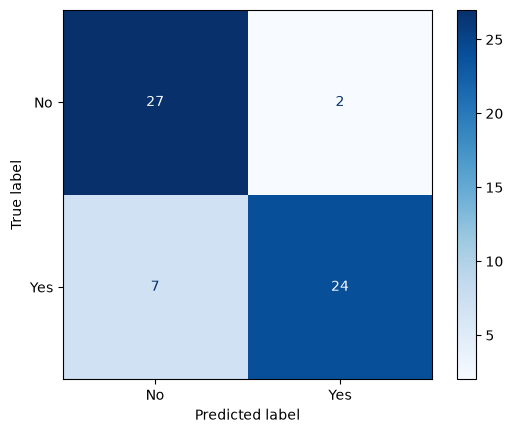

              precision    recall  f1-score   support

          No       0.79      0.93      0.86        29
         Yes       0.92      0.77      0.84        31

    accuracy                           0.85        60
   macro avg       0.86      0.85      0.85        60
weighted avg       0.86      0.85      0.85        60



In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=best_rf.classes_)
ConfusionMatrixDisplay(cm, display_labels=best_rf.classes_).plot(cmap="Blues")
plt.show()

print(classification_report(y_test, y_pred))

Compute the confusion matrix using the `confusion_matrix()` function and plot it. You can use the `ConfusionMatrixDisplay` helper, or create the plot yourself. Comment the results.

[[27  2]
 [ 7 24]]


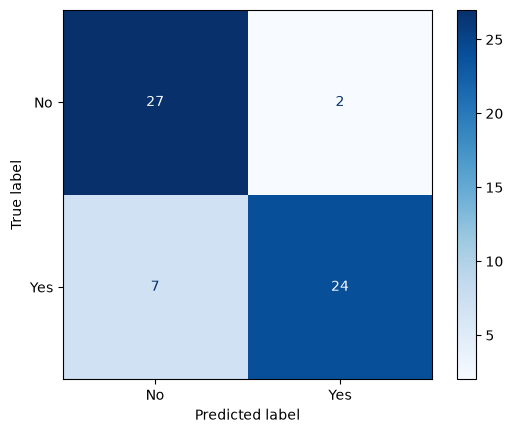

In [23]:
cm = confusion_matrix(y_test, y_pred, labels=best_rf.classes_)
print(cm)

ConfusionMatrixDisplay(cm, display_labels=best_rf.classes_).plot(cmap="Blues")
plt.show()

Perform a classification report using the `classification_report()` function, and comment the results.

In [24]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.79      0.93      0.86        29
         Yes       0.92      0.77      0.84        31

    accuracy                           0.85        60
   macro avg       0.86      0.85      0.85        60
weighted avg       0.86      0.85      0.85        60



Plot the [Receiver Operating Characteristic (ROC)](https://en.wikipedia.org/wiki/Receiver_operating_characteristic) and estimate its Area Under Curve (AUC) using `roc_curve` and `roc_auc_score`. See e.g. `RocCurveDisplay` or `RocCurveDisplay.from_estimator` for plot helpers. Comment the results.

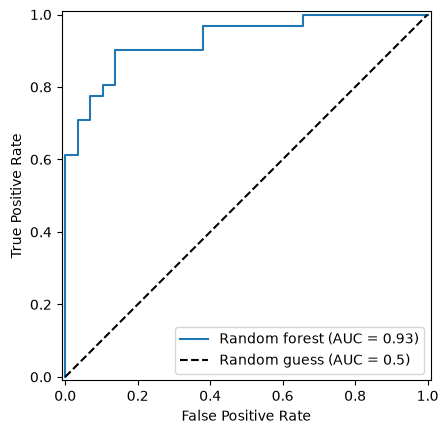

AUC: 0.930


In [25]:
from sklearn.metrics import roc_auc_score, roc_curve, RocCurveDisplay
pos = best_rf.classes_[1]                   # positive class, e.g. "Yes"
y_score = best_rf.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_score, pos_label=pos)
auc = roc_auc_score(y_test == pos, y_score)

RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=auc, name="Random forest").plot()
plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
plt.legend()
plt.show()

print(f"AUC: {auc:.3f}")

One can also have a look at the `yellowbrick` package for more pre-coded diagnostic plots (with `pip install yellowbrick` (https://www.scikit-yb.org/en/latest/)).

## 3. Theoretical Exercise: Properties of Bootstrap

We will now derive the probability that a given observation is part
of a bootstrap sample. 

Let $Z = \{Z_1, \dots, Z_n\}$ be our original sample of size $n$. (For example, $Z_i = (X_i, Y_i)$
can represent the pair of predictors and target variables for each observation $i = 1, \dots, n$.)

Let $Z^* = \{Z_1^*, \dots, Z_n^*\}$ be a bootstrap sample of size $n$, resampled from $Z$. (You can think of it as one of the $B$ bootstrap samples $Z^{*1},\ldots,Z^{*B}$ used for bagging.)

We want to show that, for each $i = 1, \dots, n$, the probability that $Z_i$ is part of the bootstrap sample is $P\left(Z_i \in Z^*\right) = 1 - 1/e$.

* What is the probability that the first bootstrap observation
is not the $i$-th observation from the original sample? 
Justify your answer.

* What is the probability that the second bootstrap observation
is not the $i$-th observation from the original sample?

* Argue that the probability that the $i$-th observation is not in the
bootstrap sample is $(1 - \frac{1}{n})^n$.

* When $n = 5$, what is the probability that the $i$-th observation is
in the bootstrap sample?

* When $n = 100$, what is the probability that the $i$-th observation
is in the bootstrap sample?

* When $n \to \infty$, what is the probability that the $i$-th observation
is in the bootstrap sample?